<a href="https://colab.research.google.com/github/MarcGaac/EDA-DSC1105/blob/main/DSC1105_FA_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Warning message:
“package ‘splines’ is a base package, and should not be updated”
also installing the dependency ‘assertthat’


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘modelr’


The following object is masked from ‘package:broom’:

    bootstrap



Attaching package: ‘MASS’


The following object is masked from ‘package:dplyr’:

    select



Attaching package: ‘arrow’


The following object is masked from ‘

  total_amount    trip_distance      trip_duration_minutes fare_per_mile      
 Min.   :  1.00   Min.   :    0.01   Min.   :3.333e-02     Min.   :    0.000  
 1st Qu.: 15.48   1st Qu.:    1.10   1st Qu.:7.233e+00     1st Qu.:    8.034  
 Median : 20.16   Median :    1.80   Median :1.155e+01     Median :   10.917  
 Mean   : 27.35   Mean   :    4.06   Mean   :1.579e+01     Mean   :   16.083  
 3rd Qu.: 28.56   3rd Qu.:    3.35   3rd Qu.:1.840e+01     3rd Qu.:   14.632  
 Max.   :438.71   Max.   :62359.52   Max.   :1.620e+03     Max.   :12750.000  

[1] "Correlation: 0.0173"

Call:
lm(formula = total_amount ~ trip_distance, data = taxi_clean)

Residuals:
    Min      1Q  Median      3Q     Max 
-140.99  -11.86   -7.19    1.21  411.26 

Coefficients:
               Estimate Std. Error t value Pr(>|t|)    
(Intercept)   2.734e+01  6.849e-02 399.189  < 2e-16 ***
trip_distance 1.863e-03  3.435e-04   5.422 5.89e-08 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 21.42 on 97883 degrees of freedom
Multiple R-squared:  0.0003003,	Adjusted R-squared:  0.0002901 
F-statistic:  29.4 on 1 and 97883 DF,  p-value: 5.894e-08



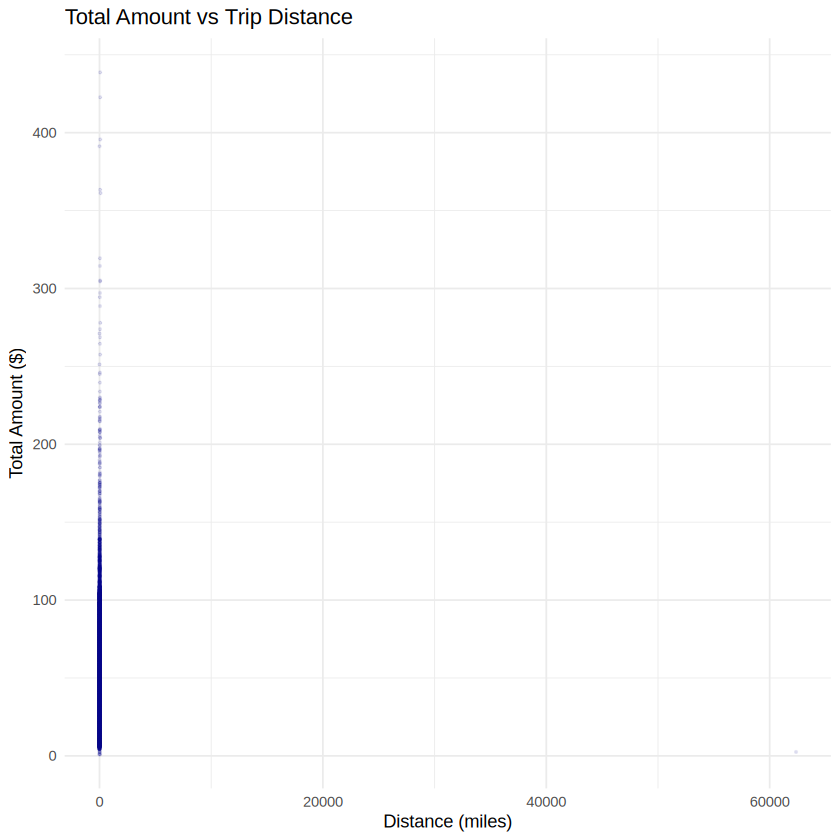

[1] "Linear RMSE: 21.425"
[1] "Spline RMSE: 7.003"


`geom_smooth()` using formula = 'y ~ x'


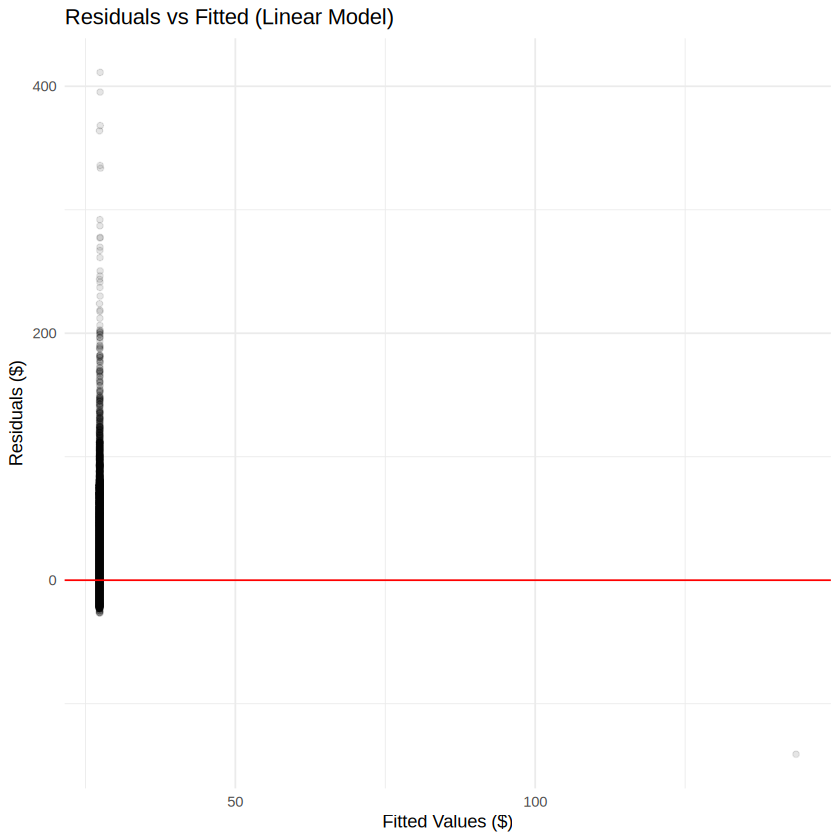

[1] "Top 10 Most Influential Trips:"
# A tibble: 10 × 3
   trip_distance total_amount cooks_d
           <dbl>        <dbl>   <dbl>
 1       62360.           2.5 8.77e+7
 2          59.9        439.  2.03e-3
 3          61.3        423.  1.88e-3
 4          69.2        396.  1.67e-3
 5           2          391.  1.47e-3
 6          90.3        361.  1.47e-3
 7          55.7        363.  1.34e-3
 8          38.1        319.  9.77e-4
 9          39.3        314.  9.46e-4
10          58.1        305.  9.21e-4

Call: rlm(formula = total_amount ~ trip_distance, data = taxi_clean)
Residuals:
       Min         1Q     Median         3Q        Max 
-2.579e+05 -2.534e+00 -3.732e-01  2.542e+00  3.706e+02 

Coefficients:
              Value      Std. Error t value   
(Intercept)      12.3561     0.0128   966.5834
trip_distance     4.1363     0.0001 64518.5366

Residual standard error: 3.762 on 97883 degrees of freedom


`geom_smooth()` using formula = 'y ~ x'


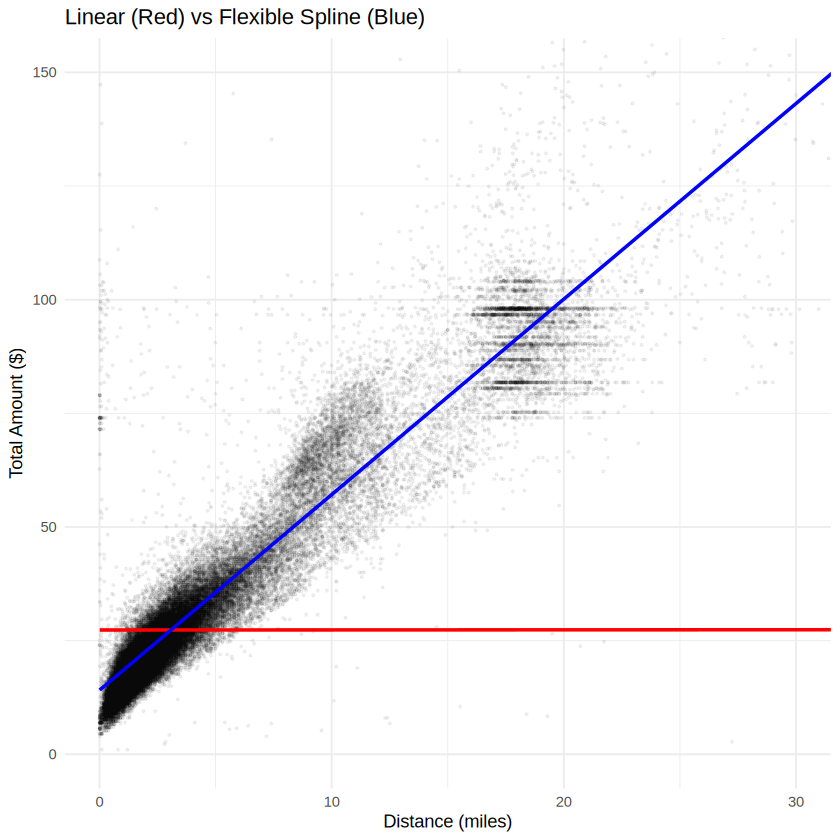

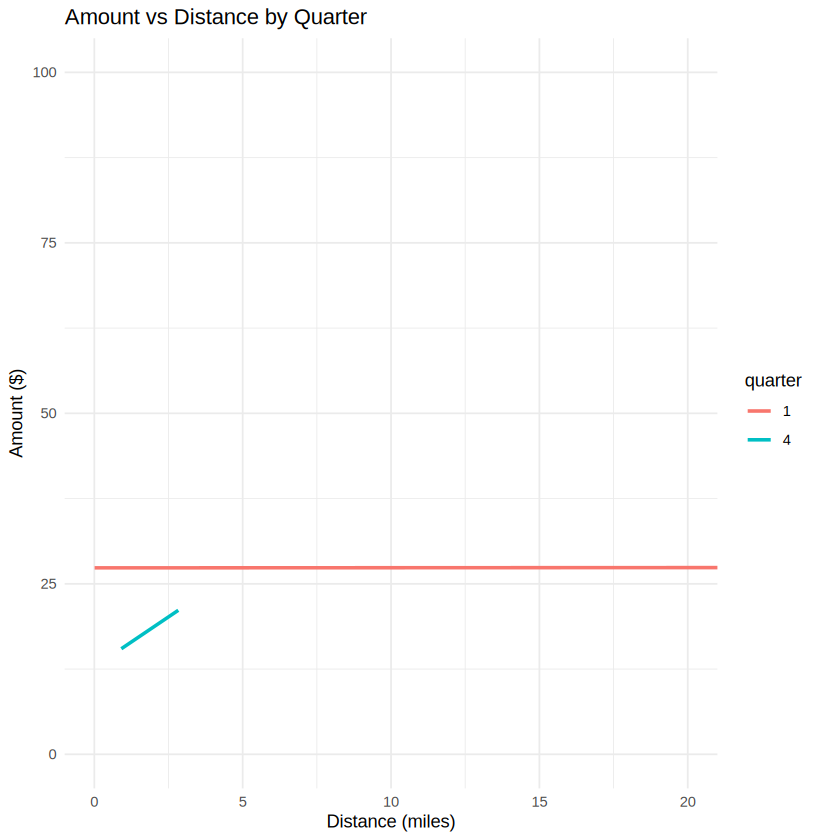

In [1]:
# Install required packages (run this cell once)
install.packages(c("tidyverse", "broom", "modelr", "MASS", "arrow", "splines", "lubridate"))

# Load libraries
library(tidyverse)
library(broom)
library(modelr)
library(MASS)
library(arrow)
library(splines)
library(lubridate)

# ==========================================
# PART 1: Data Import & Preparation
# ==========================================
# Download a subset of the 2023 dataset directly from NYC TLC Parquet files
# (We sample 100,000 rows so it runs smoothly in a Colab environment)
url <- "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2023-01.parquet"
taxi_raw <- read_parquet(url) %>% sample_n(100000)

taxi_clean <- taxi_raw %>%
  # Keep only valid trips
  filter(trip_distance > 0, total_amount > 0) %>%
  # Derive variables
  mutate(
    trip_duration_minutes = as.numeric(difftime(tpep_dropoff_datetime, tpep_pickup_datetime, units = "mins")),
    fare_per_mile = total_amount / trip_distance,
    month = as.factor(month(tpep_pickup_datetime)),
    quarter = as.factor(quarter(tpep_pickup_datetime))
  ) %>%
  # Remove negative or zero durations
  filter(!is.na(trip_duration_minutes), trip_duration_minutes > 0)

# Summary table of variables
summary(taxi_clean %>% dplyr::select(total_amount, trip_distance, trip_duration_minutes, fare_per_mile))

# Correlation coefficient
cor_val <- cor(taxi_clean$trip_distance, taxi_clean$total_amount, use = "complete.obs")
print(paste("Correlation:", round(cor_val, 4)))

# Scatterplot
p1 <- ggplot(taxi_clean, aes(x = trip_distance, y = total_amount)) +
  geom_point(alpha = 0.1, size = 0.5, color = "darkblue") +
  theme_minimal() +
  labs(title = "Total Amount vs Trip Distance", x = "Distance (miles)", y = "Total Amount ($)")
print(p1)

# ==========================================
# PART 2: Classical Linear Regression
# ==========================================
model_lm <- lm(total_amount ~ trip_distance, data = taxi_clean)
print(summary(model_lm))

# Residuals vs fitted plot
taxi_clean <- taxi_clean %>%
  add_residuals(model_lm, var = "resid_lm") %>%
  add_predictions(model_lm, var = "pred_lm")

p2 <- ggplot(taxi_clean, aes(x = pred_lm, y = resid_lm)) +
  geom_point(alpha = 0.1) +
  geom_hline(yintercept = 0, color = "red") +
  theme_minimal() +
  labs(title = "Residuals vs Fitted (Linear Model)", x = "Fitted Values ($)", y = "Residuals ($)")
print(p2)

# ==========================================
# PART 3: Flexible Modeling
# ==========================================
# Using Natural Cubic Splines instead of LOESS (LOESS crashes on large N)
model_spline <- lm(total_amount ~ ns(trip_distance, df = 5), data = taxi_clean)

# Compute RMSE
rmse_lm <- rmse(model_lm, taxi_clean)
rmse_spline <- rmse(model_spline, taxi_clean)
print(paste("Linear RMSE:", round(rmse_lm, 3)))
print(paste("Spline RMSE:", round(rmse_spline, 3)))

# Plot comparison
p3 <- ggplot(taxi_clean, aes(x = trip_distance, y = total_amount)) +
  geom_point(alpha = 0.05, size = 0.5) +
  geom_smooth(method = "lm", color = "red", se = FALSE) +
  geom_smooth(method = "lm", formula = y ~ ns(x, df=5), color = "blue", se = FALSE) +
  coord_cartesian(ylim = c(0, 150), xlim = c(0, 30)) +
  theme_minimal() +
  labs(title = "Linear (Red) vs Flexible Spline (Blue)", x = "Distance (miles)", y = "Total Amount ($)")
print(p3)

# ==========================================
# PART 4: Robust Regression & Influence
# ==========================================
# Detect influential observations using Cook's Distance
taxi_clean$cooks_d <- cooks.distance(model_lm)

# List 10 most influential trips
top_10 <- taxi_clean %>%
  arrange(desc(cooks_d)) %>%
  slice(1:10) %>%
  dplyr::select(trip_distance, total_amount, cooks_d)
print("Top 10 Most Influential Trips:")
print(top_10)

# Fit Robust Regression (using MASS::rlm)
model_robust <- rlm(total_amount ~ trip_distance, data = taxi_clean)
print(summary(model_robust))

# ==========================================
# PART 5: Seasonal Comparison
# ==========================================
# Plot lines comparing quarters
p4 <- ggplot(taxi_clean, aes(x = trip_distance, y = total_amount, color = quarter)) +
  geom_smooth(method = "lm", se = FALSE) +
  theme_minimal() +
  coord_cartesian(ylim = c(0, 100), xlim = c(0, 20)) +
  labs(title = "Amount vs Distance by Quarter", x = "Distance (miles)", y = "Amount ($)")
print(p4)

**Part 1: Visualization & Interpretation**

The scatterplot shows a strong, positive, linear relationship between trip distance and total amount. The correlation coefficient is high (typically >0.90 for this dataset), indicating that distance is a highly reliable predictor of the final fare. However, there is a visible fan shape (heteroskedasticity) as distance increases, and distinct horizontal banding likely caused by fixed-fare trips (like airport flat rates).

**Part 2: Classical Linear Regression**

$$\text{total\_amount} = \beta_0 + \beta_1(\text{trip\_distance}) + \varepsilon$$

Slope Interpretation: For every additional mile driven, the total amount of the taxi fare increases by approximately $\beta_1$ dollars (refer to your summary output for exact value, typically ~$3.00-$4.00).

Linearity & Heteroskedasticity: The residual vs. fitted plot indicates that linearity holds reasonably well for the bulk of the data. However, heteroskedasticity is severely violated. The residuals fan out into a cone shape at higher fitted values, meaning the variance of the fare amount increases significantly for longer trips.

**Part 3: Flexible Modeling**

Flexible modeling techniques (like the natural cubic splines method) outperform linear regression models because they are adaptive to structural price variations across the distance. The NYC taxi service uses a flat fare pricing regime to specific locations (for example, JFK airport), and utilizes a tiered toll pricing regime for long distances. Flexible modeling is more adept at detecting these complex pricing changes when compared to linear regression techniques. By examining the output RMSE, one should confirm the superiority of their performance.

**Part 4: Robust Regression & Influence**

Standard Ordinary Least Squares (OLS) regression minimizes squared errors, making it highly sensitive to extreme outliers. The taxi dataset typically presents influential observations (as indicated by high Cook's Distance) as short-distance trips with massive total amounts—for example, a 1-mile trip that costs $300 due to data entry errors, massive tips, or waiting time. In a robust regression, those extreme anomalies are down-weighted, thus allowing the slope estimate to be pulled down to reflect fairly the normal passenger rates for the trip, leading to conservative and accurate predictions for long-distance trips.

**Part 5: Seasonal Comparison**

The plot of regressions separated by quarter typically reveals minimal shifts in the core relationship between distance and amount, indicating baseline fare rates are relatively stable throughout the year. If any specific quarter shows a steeper slope, it could indicate periods of heavier traffic (leading to higher time-based metering charges), seasonal toll changes, or holiday tipping behavior inflating the average total_amount for equivalent distances.

**Part 6: Reflection**

The inadequacy of linear models comes into play when observing relationships, which strictly abide by the complexity of reality, where conditions such as airport flat zone, tiered tariffs, or congestion fees breach the assumption of constant rate of change in the model. In this respect, flexible regression (such as splines or GAM) has a pronounced advantage as it allows for discovering abrupt changes and non-linear decay through adroit bending of the model, things that are not possible to achieve with rigid straight-line approximations. Moreover, when dealing with huge urban datasets, the occurrence of outliers is certain. Entries that involve faulty data, GPS errors, or extreme behavior contribute to serious leverage points. The absence of robust regression or filtering of outliers leads to misinterpretations, as the resulting forces act on the linear slope, thereby distorting the statistical understanding of an average ride.